In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

# Lab 1

## 1A

For our single day I will assume our mean is 5, and that our source emissions came out to 9.

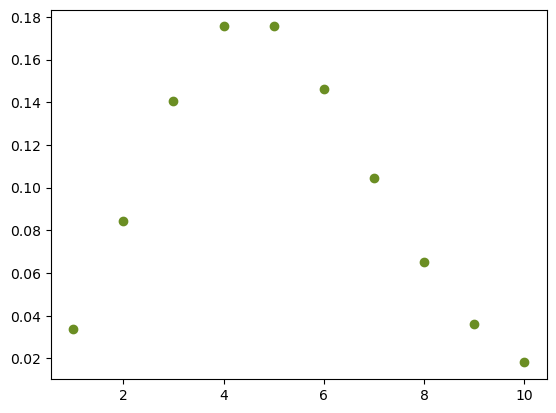

In [2]:
mu = 5
x = np.arange(stats.poisson.ppf(0.01, mu), stats.poisson.ppf(0.99, mu))
day_one = stats.poisson.pmf(x, mu)
dx = x[1] - x[0]
fig, ax = plt.subplots()

day_two = np.convolve(day_one, day_one, mode = 'full') * dx
x_two = 2*x[0] + np.arange(len(day_two))
day_three = np.convolve(day_two, day_one, mode = 'full')
x_three = 3*x[0] + np.arange(len(day_three))
day_four = np.convolve(day_three, day_one, mode = 'full')
x_four = 4*x[0] + np.arange(len(day_four))
day_five = np.convolve(day_four, day_one, mode = 'full')
x_five = 5*x[0] + np.arange(len(day_five))
ax.scatter(x, day_one, color = 'olivedrab')
    # ax[i].vlines(x, 0, stats.poisson.pmf(x, mu), colors='olivedrab', lw=5, alpha=0.5)

plt.show()


Above we have the distribution for one day.

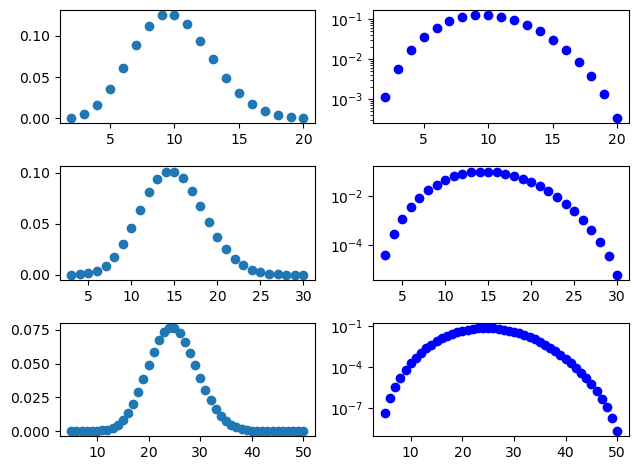

In [3]:
fig, ax = plt.subplots(3, 2)
ax[0, 0].scatter(x_two, day_two)
ax[1, 0].scatter(x_three, day_three)
ax[2, 0].scatter(x_five, day_five)
ax[0, 1].semilogy(x_two, day_two, 'bo')
ax[1, 1].semilogy(x_three, day_three, 'bo')
ax[2, 1].semilogy(x_five, day_five, 'bo')
plt.tight_layout()
plt.show()

We can see our distributions are getting a little tighter around the mean, or in this case the sum of the means.

## 1B

The semilog plot clearly demonstrates the non-gaussian nature of the distribution.

## 1C

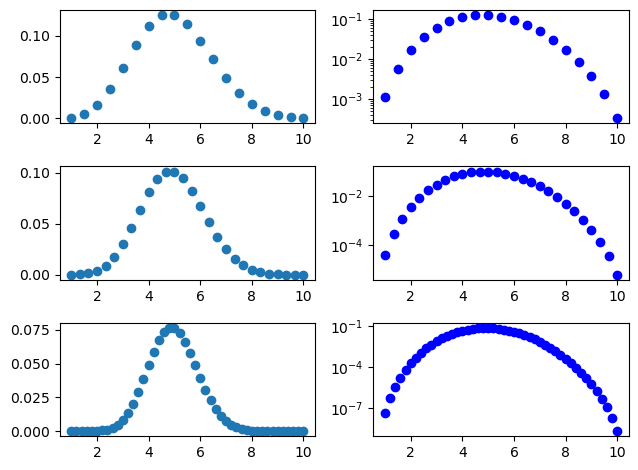

In [4]:
fig, ax = plt.subplots(3, 2)
ax[0, 0].scatter(x_two / 2, day_two)
ax[1, 0].scatter(x_three / 3, day_three)
ax[2, 0].scatter(x_five / 5, day_five)
ax[0, 1].semilogy(x_two / 2, day_two, 'bo')
ax[1, 1].semilogy(x_three / 3, day_three, 'bo')
ax[2, 1].semilogy(x_five / 5, day_five, 'bo')
plt.tight_layout()
plt.show()



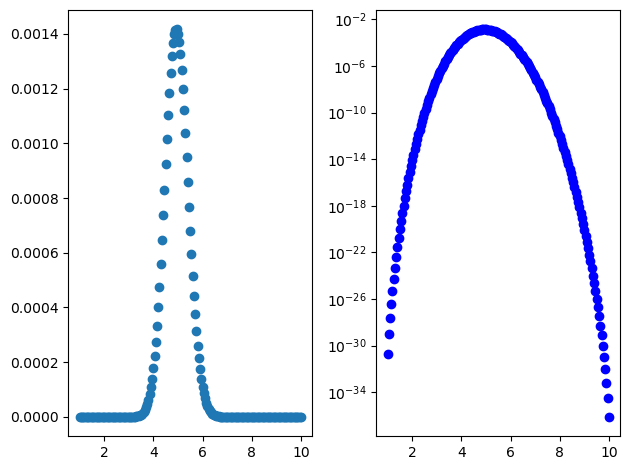

In [5]:

for i in range(15):
    day_five = np.convolve(day_five, day_one, mode = 'full')

x_twenty = 20 * x[0] + np.arange(len(day_five))
fig, ax = plt.subplots(1, 2)
ax[0].scatter(x_twenty / 20, day_five / 20)
ax[1].semilogy(x_twenty / 20, day_five / 20, 'bo')
plt.tight_layout()
plt.show()

In the above we can see the distribution slowly shifting towards Gaussian after averaging 20.

## 1D

Let's use our twenty day distribution from above.

In [9]:
signal = 1 - np.sum(day_five[0:161])
print(len(day_five))
print(x_twenty[160])
print(day_five[160])
print(np.sum(day_five))
print(signal)

# I don't understand how to use the averaged distribution here, and my attempt above is giving me a value I don't understand. 
# Like how does the sum from the 160th index to the 181st of the below array add up to .3 ???

181
180.0
1.7700034105130547e-19
0.6617302815762646
0.33826971842373554


## 2A

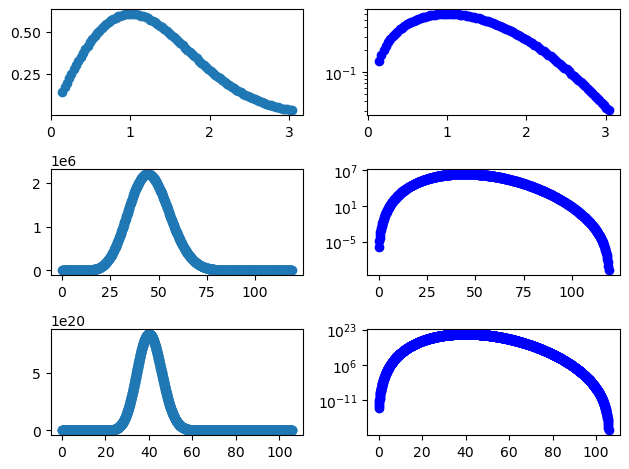

In [7]:
x_ray = np.linspace(stats.rayleigh.ppf(0.01), stats.rayleigh.ppf(0.99), 100)
rayleigh = stats.rayleigh.pdf(x_ray, loc = 0, scale = 1)
rayleigh_2 = rayleigh
for i in range(5):
    rayleigh_2 = np.convolve(rayleigh_2, rayleigh, mode = 'full')
x_ray2 = x_ray[0] + np.arange(len(rayleigh_2)) / 5
rayleigh_3 = rayleigh
for i in range(15):
    rayleigh_3 = np.convolve(rayleigh_3, rayleigh, mode = 'full')
x_ray3 = x_ray[0] + np.arange(len(rayleigh_3)) / 15

fig, ax = plt.subplots(3, 2)
ax[0, 0].scatter(x_ray, rayleigh)
ax[0,1].semilogy(x_ray, rayleigh, 'bo')
ax[1, 0].scatter(x_ray2, rayleigh_2 / 5)
ax[1, 1].semilogy(x_ray2, rayleigh_2 / 5, 'bo')
ax[2, 0].scatter(x_ray3, rayleigh_3 / 15)
ax[2, 1].semilogy(x_ray3, rayleigh_3 / 15, 'bo')
plt.tight_layout()
plt.show()


## 2B

Frankly I have no clue why the numbers get so big on the last convolution. Regardless, the semilogy plot really doesn't make it seem like it's going to become Gaussian any time soon.

## 3A

I will use a Gaussian with a std of .25 and say I got a reading of 1.7.

In [13]:
ligo = stats.norm.sf(1.7, loc = 0, scale = .25)
print(ligo)
sigma = stats.norm.ppf(ligo)
print(sigma)

5.230957544144583e-12
-6.8


-6.8 sigma is very much enough to publish.

## 3B

I am working on this currently. I apologize for how little I have accomplished this lab. To be frank, I feel extremely unprepared as we d